In [1]:
import sys
sys.path.append('../../')

import numpy as np
import pickle
import matplotlib.pyplot as plt
from numpy.linalg import norm as np_norm


from Utilities import *
import config

path = "../../Heaven_scripts/"

folder_N_100_eps_01 = path + "uns_k_-50_eps_01_N_100001/"
folder_N_100_eps_005 = path + "uns_k_-50_eps_005_N_100001/"
folder_N_100_eps_001 = path + "uns_k_-50_eps_001_N_100001/"

folder_N_25_eps_01 = path + "uns_k_-50_eps_01_N_25001_dt_0.02/"
folder_N_25_eps_005 = path + "uns_k_-50_eps_005_N_25001_dt_0.02/"
folder_N_25_eps_001 = path + "uns_k_-50_eps_001_N_25001_dt_0.02/"

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


# Preliminaries

In [2]:
# Theos
theo_eps_01 = pickle.load(open(folder_N_100_eps_01 + "theo.pck", "rb"))
theo_eps_005 = pickle.load(open(folder_N_100_eps_005 + "theo.pck", "rb"))
theo_eps_001 = pickle.load(open(folder_N_100_eps_001 + "theo.pck", "rb"))

def w_dark_eps_01(x, t):
    return theo_eps_01(x - c_in_1 * t)

def w_dark_eps_005(x, t):
    return theo_eps_005(x - c_in_2 * t)

def w_dark_eps_001(x, t):
    return theo_eps_001(x - c_in_3 * t)

In [3]:
L = 400
dt = 0.02
tf = 400
Nt = int(400//0.02)

t = np.linspace(0, tf, Nt)

# Init parameters
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps_1 = 0.1
eps_2 = 0.05
eps_3 = 0.01

c_in_1 = c_star - eps_1
c_in_2 = c_star - eps_2
c_in_3 = c_star - eps_3

# $N = 100001$ and $dt = 0.02$

In [4]:
N_1 = 100_001
x_1 = np.linspace(-L, L, N_1)
h_1 = 2*L/N_1

In [5]:
Nelem = int(Nt//10)+1

w_N_100_eps_01 = np.empty(Nelem, dtype=object)
w_N_100_eps_005 = np.empty(Nelem, dtype=object)
w_N_100_eps_001 = np.empty(Nelem, dtype=object)

file = gzip.GzipFile(folder_N_100_eps_01+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_100_eps_01[0] = w_file

file = gzip.GzipFile(folder_N_100_eps_005+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_100_eps_005[0] = w_file

file = gzip.GzipFile(folder_N_100_eps_001+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_100_eps_001[0] = w_file

for n in range(10, Nt, 10):
    file = gzip.GzipFile(folder_N_100_eps_01+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_100_eps_01[n//10] = w_file

    file = gzip.GzipFile(folder_N_100_eps_005+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_100_eps_005[n//10] = w_file

    file = gzip.GzipFile(folder_N_100_eps_001+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_100_eps_001[n//10] = w_file

KeyboardInterrupt: 

In [ ]:
j = 350
t_plot = dt * j * 10
plt.plot(x_1, norm(w_N_100_eps_01[j]), label="Simulation")
plt.plot(x_1, norm(w_dark_eps_01(x_1, t_plot)), label="Theoretical")
plt.legend()
plt.show()

In [ ]:
fig = plt.figure(figsize = (3.3, 2.5)) 
ax = plt.axes(projection = '3d') 
ax.grid(False)

ax.xaxis.pane.set_edgecolor('black')
ax.yaxis.pane.set_edgecolor('black')
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.xaxis._axinfo['tick']['inward_factor'] = 0.2
ax.xaxis._axinfo['tick']['outward_factor'] = 0.2
ax.yaxis._axinfo['tick']['inward_factor'] = 0.2
ax.yaxis._axinfo['tick']['outward_factor'] = 0.2
ax.zaxis._axinfo['tick']['inward_factor'] = 0.2
ax.zaxis._axinfo['tick']['outward_factor'] = 0.2

for j in range(0, len(w_N_100_eps_01)-1500, 30):
    ax.plot(x_1, t[j], norm(w_N_100_eps_01[j]), "-", color="black", lw=.2)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel(r"$|\psi|^2$")
plt.gcf().set_dpi(300)

ax.view_init(20, -70)
plt.show()

In [ ]:
plt.plot(x_1, np.imag(w_N_100_eps_001[-1]))
plt.plot(x_1, np.imag(w_dark_eps_001(x_1, 400)))
plt.show()

# $N = 25001$ and $dt = 0.02$

In [ ]:
N_2 = 25_001
x_2 = np.linspace(-L, L, N_2)
h_2 = 2*L/N_2

In [ ]:
Nelem = int(Nt//10)+1

w_N_25_eps_01 = np.empty(Nelem, dtype=object)
w_N_25_eps_005 = np.empty(Nelem, dtype=object)
w_N_25_eps_001 = np.empty(Nelem, dtype=object)

file = gzip.GzipFile(folder_N_25_eps_01+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_25_eps_01[0] = w_file

file = gzip.GzipFile(folder_N_25_eps_005+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_25_eps_005[0] = w_file

file = gzip.GzipFile(folder_N_25_eps_001+'w_'+f'{1:010d}'+'.npy.gz', "r")
w_file = np.load(file)
w_N_25_eps_001[0] = w_file

for n in range(10, Nt, 10):
    file = gzip.GzipFile(folder_N_25_eps_01+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_25_eps_01[n//10] = w_file

    file = gzip.GzipFile(folder_N_25_eps_005+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_25_eps_005[n//10] = w_file

    file = gzip.GzipFile(folder_N_25_eps_001+'w_'+f'{n:010d}'+'.npy.gz', "r")
    w_file = np.load(file)
    w_N_25_eps_001[n//10] = w_file

# Energy and error comparison

In [ ]:
energy_N_100_eps_01 = get_energy(w_N_100_eps_01, h_1)
energy_N_100_eps_005 = get_energy(w_N_100_eps_005, h_1)
energy_N_100_eps_001 = get_energy(w_N_100_eps_001, h_1)

In [ ]:
error_N_100_eps_01 = get_errors(w_N_100_eps_01, w_dark_eps_01, tf, h_1, x_1, p)
error_N_100_eps_005 = get_errors(w_N_100_eps_005, w_dark_eps_005, tf, h_1, x_1, p)
error_N_100_eps_001 = get_errors(w_N_100_eps_001, w_dark_eps_001, tf, h_1, x_1, p)

In [ ]:
energy_N_25_eps_01 = get_energy(w_N_25_eps_01, h_2)
energy_N_25_eps_005 = get_energy(w_N_25_eps_005, h_2)
energy_N_25_eps_001 = get_energy(w_N_25_eps_001, h_2)

In [ ]:
error_N_25_eps_01 = get_errors(w_N_25_eps_01, w_dark_eps_01, tf, h_2, x_2, p)
error_N_25_eps_005 = get_errors(w_N_25_eps_005, w_dark_eps_005, tf, h_2, x_2, p)
error_N_25_eps_001 = get_errors(w_N_25_eps_001, w_dark_eps_001, tf, h_2, x_2, p)

In [ ]:
plt.plot(t[::10], energy_N_25_eps_01, label="N=25.000")
plt.plot(t[::10], energy_N_100_eps_01, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)$")
plt.legend()
plt.show()
plt.plot(t[::10], energy_N_25_eps_005, label="N=25.000")
plt.plot(t[::10], energy_N_100_eps_005, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)$")
plt.legend()
plt.show()
plt.plot(t[::10], energy_N_25_eps_001, label="N=25.000")
plt.plot(t[::10], energy_N_100_eps_001, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)$")
plt.legend()
plt.show()

In [ ]:
plt.plot(t[::10], error_N_25_eps_01, label="N=25.000")
plt.plot(t[::10], error_N_100_eps_01, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$||\psi_{num} - \psi_{theo}||_\infty$")
plt.legend()
plt.show()
plt.plot(t[::10], error_N_25_eps_005, label="N=25.000")
plt.plot(t[::10], error_N_100_eps_005, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$||\psi_{num} - \psi_{theo}||_\infty$")
plt.legend()
plt.show()
plt.plot(t[::10], error_N_25_eps_001, label="N=25.000")
plt.plot(t[::10], error_N_100_eps_001, label="N=100.000")
plt.xlabel(r"$t$")
plt.ylabel(r"$||\psi_{num} - \psi_{theo}||_\infty$")
plt.legend()
plt.show()

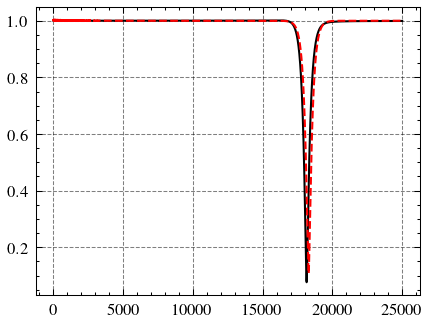

In [39]:
j = 1999
t_plot = dt * j * 10

plt.plot(norm(w_N_25_eps_001[j]))
plt.plot(norm(w_dark_eps_001(x_2, t_plot)))
plt.show()

## For properties

In [ ]:
file_e = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/energy.npy.gz", "r")
file_m = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/mass.npy.gz", "r")
file_er_2 = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/error_L2.npy.gz", "r")
file_er_inf = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/error_inf.npy.gz", "r")
file_grad_2 = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/grad_L2.npy.gz", "r")
file_grad_inf = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/grad_inf.npy.gz", "r")
file_time = gzip.GzipFile("uns_k_-50_eps_01_N_8001_dt_0.1/time.npy.gz", "r")

mass = np.load(file_m)
energy = np.load(file_e)
error_2 = np.load(file_er_2)
error_inf = np.load(file_er_inf)
grad_2 = np.load(file_grad_2)
grad_inf = np.load(file_grad_inf)
t_plot = np.load(file_time)

In [ ]:
plt.plot(t_plot, mass)
plt.show()
plt.plot(t_plot, energy)
plt.show()
plt.plot(t_plot, error_2)
plt.show()
plt.plot(t_plot, error_inf)
plt.show()
plt.plot(t_plot, grad_2)
plt.show()
plt.plot(t_plot, grad_inf)
plt.show()